# CISC7204 Assignment 02
## Premier League Teams with Similar Points

**CHEN IAT HONG:** MC654102  
**TANG CHI IN:** MC660146

Calculate team statistics and compare equal-point clubs using radar charts
and grouped bars. Run the cells in order with the three CSV files beside
this notebook. The figures are displayed here and saved as PNG files.

## Step 1 Load the data

Read the match and player data. Use the A1-derived summary only to check
the statistics calculated from the match records.

In [1]:
from pathlib import Path
from itertools import combinations
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 20)
pd.set_option('display.precision', 3)

In [2]:
data_dir = Path('.')
matches = pd.read_csv(data_dir / 'season-2526.csv', encoding='utf-8-sig')
players = pd.read_csv(data_dir / 'players_data-2025_2026.csv', encoding='utf-8-sig')
a1_summary = pd.read_csv(data_dir / 'team_analysis.csv', encoding='utf-8-sig')

print(f'Loaded {len(matches)} fixtures, {len(players)} player-club records and {len(a1_summary)} A1 summary rows.')

Loaded 380 fixtures, 2839 player-club records and 20 A1 summary rows.


## Step 2 Validate the match records

Check duplicate fixtures, numerical counts and result codes. The schedule
must cover 20 clubs with 19 home and 19 away games each.


In [3]:
match_dates = pd.to_datetime(matches['Date'], format='%Y-%m-%d', errors='raise')
match_key = ['Date', 'HomeTeam', 'AwayTeam']
count_columns = ['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST',
                 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']
assert len(matches) == 380
assert matches[match_key].notna().all().all()
assert not matches.duplicated(match_key).any()
assert not matches.duplicated(['HomeTeam', 'AwayTeam']).any()
assert (matches['HomeTeam'] != matches['AwayTeam']).all()

match_counts = matches[count_columns].apply(pd.to_numeric, errors='raise')
assert np.isfinite(match_counts.to_numpy()).all()
assert (match_counts >= 0).all().all()
assert (match_counts % 1 == 0).all().all()
assert (matches['HST'] <= matches['HS']).all()
assert (matches['AST'] <= matches['AS']).all()

In [4]:
expected_results = np.select(
    [matches['FTHG'] > matches['FTAG'], matches['FTHG'] < matches['FTAG']],
    ['H', 'A'], default='D'
)
assert (matches['FTR'] == expected_results).all()
home_counts = matches['HomeTeam'].value_counts()
away_counts = matches['AwayTeam'].value_counts()
assert len(home_counts) == 20 and set(home_counts.index) == set(away_counts.index)
assert home_counts.eq(19).all() and away_counts.eq(19).all()
print(f'Validated {len(matches)} fixtures from {match_dates.min():%Y-%m-%d} to {match_dates.max():%Y-%m-%d}.')

Validated 380 fixtures from 2025-08-15 to 2026-05-24.


## Step 3 Create one record for each team in a fixture

Convert home and away views to the same columns, giving 760 team-match
records. Calculate goal margins and award three points for a win and one
for a draw, without administrative adjustments.


In [5]:
home = matches[['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'HS', 'HST', 'AST']].rename(columns={
    'HomeTeam': 'Team', 'AwayTeam': 'Opponent', 'FTHG': 'GF', 'FTAG': 'GA',
    'HS': 'Shots', 'HST': 'ShotsOnTarget', 'AST': 'ShotsOnTargetAgainst'
})
home['Venue'] = 'Home'

away = matches[['Date', 'AwayTeam', 'HomeTeam', 'FTAG', 'FTHG', 'AS', 'AST', 'HST']].rename(columns={
    'AwayTeam': 'Team', 'HomeTeam': 'Opponent', 'FTAG': 'GF', 'FTHG': 'GA',
    'AS': 'Shots', 'AST': 'ShotsOnTarget', 'HST': 'ShotsOnTargetAgainst'
})
away['Venue'] = 'Away'

In [6]:
team_matches = pd.concat([home, away], ignore_index=True)
team_matches['GoalMargin'] = team_matches['GF'] - team_matches['GA']
team_matches['Result'] = np.select(
    [team_matches['GoalMargin'] > 0, team_matches['GoalMargin'] < 0], ['W', 'L'], default='D'
)
team_matches['Points'] = np.select(
    [team_matches['Result'].eq('W'), team_matches['Result'].eq('D')], [3, 1], default=0
)
assert len(team_matches) == 760

## Step 4 Calculate the team-season measures

Group by the standardised Team key, sum the match counts and calculate
per-match rates. Shot accuracy is shots on target divided by all shots.
Check that goals and shots on target balance across the league.


In [7]:
totals = ['GF', 'GA', 'Shots', 'ShotsOnTarget', 'ShotsOnTargetAgainst', 'Points']
teams = team_matches.groupby('Team')[totals].sum()
teams['Played'] = team_matches.groupby('Team').size()

teams['GoalsPerMatch'] = teams['GF'] / teams['Played']
teams['ConcededPerMatch'] = teams['GA'] / teams['Played']
teams['ShotsPerMatch'] = teams['Shots'] / teams['Played']
teams['SOTPerMatch'] = teams['ShotsOnTarget'] / teams['Played']
teams['OppSOTPerMatch'] = teams['ShotsOnTargetAgainst'] / teams['Played']
teams['ShotAccuracy'] = teams['ShotsOnTarget'] / teams['Shots']
teams['GoalsToShotsRatio'] = teams['GF'] / teams['Shots']
teams['GoalDifference'] = teams['GF'] - teams['GA']
teams = teams.reset_index().sort_values(['Points', 'Team'], ascending=[False, True]).reset_index(drop=True)

assert teams['Played'].eq(38).all()
assert teams['GF'].sum() == teams['GA'].sum()
assert teams['ShotsOnTarget'].sum() == teams['ShotsOnTargetAgainst'].sum()

## Step 5 Verify the rebuilt statistics

Compare 12 fields across 20 clubs with the A1-derived table, allowing
numerical tolerance of 1e-10. All 240 comparisons should match. This checks
internal consistency, not agreement with official match reports.


In [8]:
fields = ['GF', 'GA', 'Shots', 'ShotsOnTarget', 'ShotsOnTargetAgainst', 'Points',
          'Played', 'GoalsPerMatch', 'ConcededPerMatch', 'ShotsPerMatch',
          'OppSOTPerMatch', 'ShotAccuracy']
assert a1_summary['Team'].is_unique
assert set(a1_summary['Team']) == set(teams['Team'])
previous = a1_summary.set_index('Team')
rebuilt = teams.set_index('Team')
comparisons = []

In [9]:
for club in rebuilt.index:
    for field in fields:
        old, new = float(previous.loc[club, field]), float(rebuilt.loc[club, field])
        comparisons.append({
            'Team': club, 'Field': field, 'A1SummaryValue': old,
            'RebuiltValue': new, 'Difference': new - old,
            'Matches': bool(np.isclose(old, new, rtol=1e-10, atol=1e-10))
        })

reconciliation = pd.DataFrame(comparisons)
print('Field comparisons:', len(reconciliation))
print('Mismatches:', int((~reconciliation['Matches']).sum()))
assert len(reconciliation) == 240 and reconciliation['Matches'].all()

Field comparisons: 240
Mismatches: 0


## Step 6 Prepare the player records

Keep Premier League rows, standardise club names and check player-club
duplicates and numerical fields. Transferred players retain separate club
records; names are not verified unique person identifiers.


In [10]:
club_names = {
    'Leeds United': 'Leeds', 'Manchester City': 'Man City',
    'Manchester Utd': 'Man United', 'Newcastle United': 'Newcastle',
    'Nottingham Forest': "Nott'm Forest", 'Tottenham Hotspur': 'Tottenham',
    'West Ham United': 'West Ham'
}
epl_players = players.loc[players['Comp'].eq('eng Premier League')].copy()
epl_players['Team'] = epl_players['Squad'].replace(club_names)

assert epl_players[['Player', 'Team']].notna().all().all()
assert not epl_players.duplicated(['Player', 'Team']).any()
assert set(epl_players['Team']) == set(teams['Team'])
for column in ['Gls', 'OG', 'Min']:
    epl_players[column] = pd.to_numeric(epl_players[column], errors='raise')
    assert np.isfinite(epl_players[column]).all() and epl_players[column].ge(0).all()
assert (epl_players[['Gls', 'OG']] % 1 == 0).all().all()

print(f'Validated {len(epl_players)} player-club records across {epl_players.Team.nunique()} clubs.')

Validated 551 player-club records across 20 clubs.


## Step 7 Calculate player goal concentration

Leading-scorer and top-three shares divide those players' goals by the
club's total player-attributed goals. No minutes threshold is applied:
these are full-season contributions, not scoring rates. Alphabetical
sorting resolves display ties without changing the shares.


In [11]:
ranked_players = epl_players.sort_values(['Team', 'Gls', 'Player'], ascending=[True, False, True])
player_groups = ranked_players.groupby('Team')
goal_shares = player_groups.agg(
    PlayerClubRecords=('Player', 'size'), PlayerAttributedGoals=('Gls', 'sum'),
    OwnGoalsCommitted=('OG', 'sum')
)

leaders = player_groups.head(1).set_index('Team')
goal_shares['LeadingScorer'] = leaders['Player']
goal_shares['TopScorerGoals'] = leaders['Gls']
goal_shares['TopThreeGoals'] = player_groups.head(3).groupby('Team')['Gls'].sum()

In [12]:
assert goal_shares['PlayerAttributedGoals'].gt(0).all()
goal_shares['TopScorerShare'] = goal_shares['TopScorerGoals'] / goal_shares['PlayerAttributedGoals']
goal_shares['TopThreeShare'] = goal_shares['TopThreeGoals'] / goal_shares['PlayerAttributedGoals']
goal_shares = goal_shares.reset_index()
assert goal_shares['TopScorerShare'].le(goal_shares['TopThreeShare']).all()
assert goal_shares['TopThreeShare'].between(0, 1).all()

## Step 8 Reconcile the two goal sources

Team goals and player-attributed goals are not interchangeable. Compare
league totals without assigning unexplained goals to players. A matching
league-wide own-goal total does not verify attribution for each club.
Unreconciled goalkeeper measures remain excluded.


In [13]:
source_check = teams[['Team', 'GF']].rename(columns={'GF': 'TeamGoals'}).merge(
    goal_shares[['Team', 'PlayerAttributedGoals', 'OwnGoalsCommitted']],
    on='Team', validate='one_to_one'
)
source_check['TeamGoalsMinusPlayerGoals'] = source_check['TeamGoals'] - source_check['PlayerAttributedGoals']

team_goal_total = int(source_check['TeamGoals'].sum())
player_goal_total = int(source_check['PlayerAttributedGoals'].sum())
own_goal_total = int(source_check['OwnGoalsCommitted'].sum())
print('Team goals:', team_goal_total)
print('Player-attributed goals:', player_goal_total)
print('Goal gap:', team_goal_total - player_goal_total)
print('League-wide own goals committed:', own_goal_total)
print('The totals agree at league level; club-level own-goal attribution is not verified.')

Team goals: 1045
Player-attributed goals: 1005
Goal gap: 40
League-wide own goals committed: 40
The totals agree at league level; club-level own-goal attribution is not verified.


In [14]:
keeper_source_columns = ['SOTSourceDifference', 'GASourceDifference']
if all(column in a1_summary for column in keeper_source_columns):
    for column in keeper_source_columns:
        difference = pd.to_numeric(a1_summary[column], errors='raise')
        print(f'{column}: {int(difference.ne(0).sum())} clubs with a source difference')
print('Unreconciled goalkeeper measures are excluded from the main analysis.')

SOTSourceDifference: 20 clubs with a source difference
GASourceDifference: 1 clubs with a source difference
Unreconciled goalkeeper measures are excluded from the main analysis.


## Step 9 Identify equal-point and near-point pairs

Consider each unordered pair once. Include every exact-point case, use a
three-point window for near-point comparisons, and five points as a
sensitivity check. These windows overlap and the pairs are not independent.


In [15]:
profiles = teams.merge(goal_shares, on='Team', validate='one_to_one')
team_records = profiles.to_dict('records')
pair_records = []
pair_metrics = ['GF', 'GA', 'GoalsPerMatch', 'ConcededPerMatch', 'ShotsPerMatch',
                'SOTPerMatch', 'OppSOTPerMatch', 'ShotAccuracy', 'GoalsToShotsRatio',
                'TopScorerShare', 'TopThreeShare']

for left, right in combinations(team_records, 2):
    gap = abs(left['Points'] - right['Points'])
    row = {'TeamA': left['Team'], 'TeamB': right['Team'],
           'PointsA': left['Points'], 'PointsB': right['Points'], 'PointsGap': gap,
           'EqualPoints': gap == 0, 'WithinThreePoints': gap <= 3}
    for metric in pair_metrics:
        row[metric + 'A'], row[metric + 'B'] = left[metric], right[metric]
    pair_records.append(row)

In [16]:
all_pairs = pd.DataFrame(pair_records).sort_values(
    ['PointsGap', 'PointsA', 'TeamA', 'TeamB'], ascending=[True, False, True, True]
).reset_index(drop=True)
equal_pairs = all_pairs.loc[all_pairs['PointsGap'].eq(0)].copy()
near_pairs = all_pairs.loc[all_pairs['PointsGap'].le(3)].copy()
within_five = all_pairs.loc[all_pairs['PointsGap'].le(5)].copy()
print('All unordered pairs:', len(all_pairs))
print('Equal points:', len(equal_pairs))
print('Gap at most 3 points, including exact pairs:', len(near_pairs))
print('Gap at most 5 points, including the previous groups:', len(within_five))
equal_pairs[['TeamA', 'TeamB', 'PointsA', 'PointsB', 'PointsGap']]

All unordered pairs: 190
Equal points: 3
Gap at most 3 points, including exact pairs: 25
Gap at most 5 points, including the previous groups: 44


,TeamA,TeamB,PointsA,PointsB,PointsGap
0,Brentford,Brighton,53,53,0
1,Chelsea,Fulham,52,52,0
2,Everton,Newcastle,49,49,0


## Step 10 Compare the selected team profiles

Retain all six clubs in the exact-point cases. Rates use matches played;
the displayed shooting and scorer shares are percentages, while analytical
columns remain numeric proportions.


In [17]:
case_names = [club for row in equal_pairs.to_dict('records') for club in [row['TeamA'], row['TeamB']]]
case_profiles = profiles.set_index('Team').loc[case_names].reset_index()
case_table = case_profiles[['Team', 'Points', 'GF', 'GA', 'ShotsPerMatch', 'OppSOTPerMatch',
                            'ShotAccuracy', 'TopScorerShare', 'TopThreeShare']].copy()
for column in ['ShotAccuracy', 'TopScorerShare', 'TopThreeShare']:
    case_table[column + 'Pct'] = 100 * case_table.pop(column)
case_table.round(2)

,Team,Points,GF,GA,ShotsPerMatch,OppSOTPerMatch,ShotAccuracyPct,TopScorerSharePct,TopThreeSharePct
0,Brentford,53,55,52,10.66,4.26,36.30,41.51,69.81
1,Brighton,53,52,46,13.03,3.89,35.56,25.49,43.14
2,Chelsea,52,58,52,13.45,4.11,32.09,26.32,61.40
3,Fulham,52,47,51,12.66,3.92,28.69,23.26,53.49
4,Everton,49,47,50,11.05,4.26,34.29,20.00,55.56
5,Newcastle,49,53,55,12.95,4.42,35.77,16.98,45.28


## Step 11 Compare match outcomes

Count wins, draws, losses, clean sheets and one-goal wins for each club.

In [18]:
results = team_matches.assign(
    Win=team_matches['Result'].eq('W').astype(int),
    Draw=team_matches['Result'].eq('D').astype(int),
    Loss=team_matches['Result'].eq('L').astype(int),
    CleanSheet=team_matches['GA'].eq(0).astype(int),
    OneGoalWin=team_matches['GoalMargin'].eq(1).astype(int)
)

outcomes = results.groupby('Team').agg(
    Points=('Points', 'sum'), Wins=('Win', 'sum'), Draws=('Draw', 'sum'),
    Losses=('Loss', 'sum'), CleanSheets=('CleanSheet', 'sum'), OneGoalWins=('OneGoalWin', 'sum')
)

In [19]:
assert outcomes['Points'].eq(3 * outcomes['Wins'] + outcomes['Draws']).all()
assert (outcomes['Wins'] + outcomes['Draws'] + outcomes['Losses']).eq(38).all()
outcomes.loc[case_names, ['Points', 'Wins', 'Draws', 'Losses', 'CleanSheets', 'OneGoalWins']]

,Points,Wins,Draws,Losses,CleanSheets,OneGoalWins
Team,,,,,,
Brentford,53,14,11,13,10,5
Brighton,53,14,11,13,10,6
Chelsea,52,14,10,14,9,4
Fulham,52,15,7,16,9,10
Everton,49,13,10,15,11,7
Newcastle,49,14,7,17,8,8


## Step 12 Create radar charts and grouped bars

Use radar charts from Exercise 6.04 and grouped bars from Activity 6.02.
Display each completed figure and save it as a 300 dpi PNG beside the notebook.

In [20]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='notebook')
team_colours = ['#2878B5', '#C66B21']

### 12.1 Select five measures for the radar charts

Select goal rates, shots, opponent shots on target and leading-scorer share.
Keep the original values in a table before scaling.

In [21]:
radar_metrics = ['GoalsPerMatch', 'ConcededPerMatch', 'ShotsPerMatch',
                 'OppSOTPerMatch', 'TopScorerShare']
radar_labels = ['Goals scored\nper match', 'Goals conceded\nper match',
                'Shots\nper match', 'Opponent shots on\ntarget per match',
                'Leading scorer\nshare']
radar_raw = profiles.set_index('Team')[radar_metrics]
radar_raw.loc[case_names].round(3)

,GoalsPerMatch,ConcededPerMatch,ShotsPerMatch,OppSOTPerMatch,TopScorerShare
Team,,,,,
Brentford,1.447,1.368,10.658,4.263,0.415
Brighton,1.368,1.211,13.026,3.895,0.255
Chelsea,1.526,1.368,13.447,4.105,0.263
Fulham,1.237,1.342,12.658,3.921,0.233
Everton,1.237,1.316,11.053,4.263,0.200
Newcastle,1.395,1.447,12.947,4.421,0.170


### 12.2 Find the league-wide minimum and maximum

Calculate each measure's range across all 20 clubs. Use the same bounds for every pair.

In [22]:
radar_min = radar_raw.min()
radar_max = radar_raw.max()
radar_range = radar_max - radar_min
assert radar_raw.shape == (20, 5) and radar_raw.notna().all().all()
assert radar_range.gt(0).all()
radar_bounds = pd.DataFrame({'League minimum': radar_min, 'League maximum': radar_max})
radar_bounds

,League minimum,League maximum
GoalsPerMatch,0.711,2.026
ConcededPerMatch,0.711,1.974
ShotsPerMatch,9.342,15.684
OppSOTPerMatch,2.368,5.684
TopScorerShare,0.115,0.415


### 12.3 Scale each measure from 0 to 100

Use 100 × (value − minimum) / (maximum − minimum). These are league-wide
endpoints, not percentiles. Defensive measures are not reversed, so higher
values are not always better. Polygon area is not an overall team rating.

In [23]:
radar_scaled = 100 * (radar_raw - radar_min) / radar_range
assert np.isfinite(radar_scaled.to_numpy()).all()
assert radar_scaled.ge(-1e-10).all().all() and radar_scaled.le(100 + 1e-10).all().all()
assert np.allclose(radar_scaled.min(), 0) and np.allclose(radar_scaled.max(), 100)
radar_scaled.loc[case_names].round(1)

,GoalsPerMatch,ConcededPerMatch,ShotsPerMatch,OppSOTPerMatch,TopScorerShare
Team,,,,,
Brentford,56.0,52.1,20.7,57.1,100.0
Brighton,50.0,39.6,58.1,46.0,46.6
Chelsea,62.0,52.1,64.7,52.4,49.3
Fulham,40.0,50.0,52.3,46.8,39.1
Everton,40.0,47.9,27.0,57.1,28.2
Newcastle,52.0,58.3,56.8,61.9,18.2


### 12.4 Prepare the radar angles

Space the five measures equally and repeat the first angle to close each polygon.

In [24]:
angles = np.linspace(0, 2 * np.pi, len(radar_metrics), endpoint=False)
closed_angles = np.append(angles, angles[0])
pair_records_for_charts = equal_pairs.to_dict('records')
main_pair = next(pair for pair in pair_records_for_charts
                 if {pair['TeamA'], pair['TeamB']} == {'Brentford', 'Brighton'})
other_pairs = [pair for pair in pair_records_for_charts if pair is not main_pair]

### 12.5 Draw the team profiles

Use a short function to draw each pair with different colours, lines and markers.

In [25]:
def draw_radar_pair(ax, clubs):
    for index, club in enumerate(clubs):
        values = radar_scaled.loc[club].to_numpy(dtype=float)
        closed_values = np.append(values, values[0])
        ax.plot(closed_angles, closed_values, color=team_colours[index],
                linewidth=2, linestyle='-' if index == 0 else '--',
                marker='o' if index == 0 else 'D', markersize=4, label=club)
        ax.fill(closed_angles, closed_values, color=team_colours[index], alpha=0.08)

### 12.6 Add the radar labels and scale

Start at the top and move clockwise. Apply the same labels and 0–100 scale to every chart.

In [26]:
def format_radar(ax, title):
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angles)
    labels = ax.set_xticklabels(radar_labels, fontsize=11)
    for label, alignment in zip(labels, ['center', 'left', 'left', 'right', 'right']):
        label.set_ha(alignment)
    ax.tick_params(axis='x', pad=13)
    ax.set_ylim(0, 100)
    ax.set_yticks([25, 50, 75, 100])
    ax.set_yticklabels(['25', '50', '75', '100'], fontsize=9)
    ax.set_rlabel_position(12)
    ax.grid(color='#D6DCE1', linewidth=0.7)
    ax.spines['polar'].set_color('#B8C1C9')
    ax.set_title(title, fontsize=13, pad=18)

### 12.7 Plot Brentford and Brighton

Create the polar axis, draw both teams and add the legend.

In [27]:
fig_radar, ax_radar = plt.subplots(figsize=(6.4, 4.7), subplot_kw={'projection': 'polar'}, dpi=150)
plt.close(fig_radar)
fig_radar.subplots_adjust(left=0.20, right=0.80, bottom=0.29, top=0.78)
draw_radar_pair(ax_radar, ['Brentford', 'Brighton'])
format_radar(ax_radar, 'Brentford and Brighton (53 points)')
ax_radar.legend(loc='center', bbox_to_anchor=(0.5, 0.13),
                bbox_transform=fig_radar.transFigure, ncol=2, frameon=False, fontsize=11)

### 12.8 Display and save Figure 1

Add a scale note, save the PNG and display the completed chart.

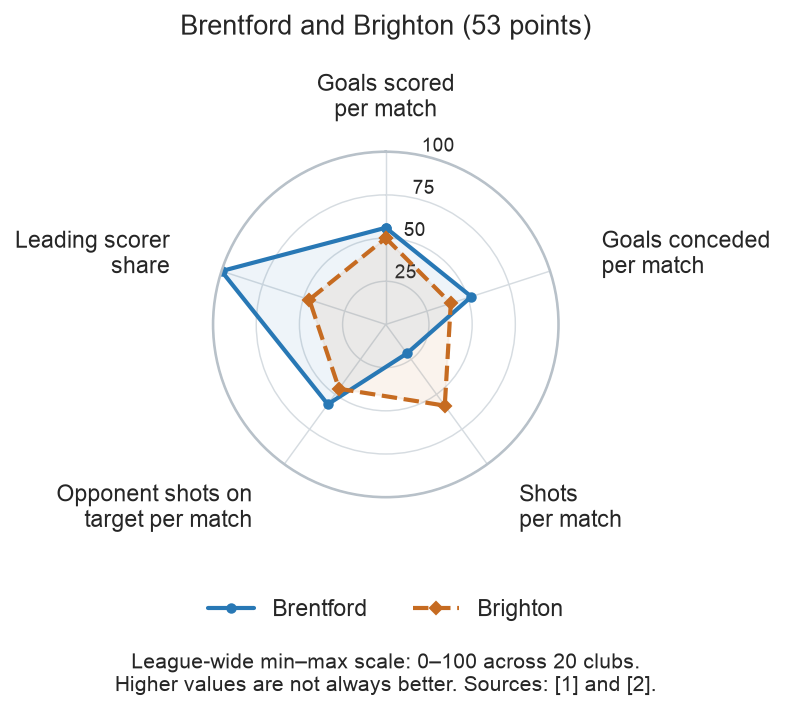

Saved PNG: team_attack_defence_profiles.png


In [28]:
fig_radar.text(0.5, 0.015,
               'League-wide min–max scale: 0–100 across 20 clubs.\n'
               'Higher values are not always better. Sources: [1] and [2].',
               ha='center', fontsize=10)
radar_png_path = data_dir / 'team_attack_defence_profiles.png'
fig_radar.savefig(radar_png_path, dpi=300, bbox_inches='tight', facecolor='white')
display(fig_radar)
print('Saved PNG:', radar_png_path.name)

### 12.9 Plot the other equal-point pairs

Repeat the same radar method for Chelsea/Fulham and Everton/Newcastle.

In [29]:
fig_other, axes_other = plt.subplots(1, 2, figsize=(11.8, 4.7),
                                    subplot_kw={'projection': 'polar'}, dpi=150)
plt.close(fig_other)
fig_other.subplots_adjust(left=0.12, right=0.88, bottom=0.29, top=0.78, wspace=0.95)
for ax, pair in zip(axes_other, other_pairs):
    draw_radar_pair(ax, [pair['TeamA'], pair['TeamB']])
    format_radar(ax, f"{pair['TeamA']} and {pair['TeamB']} ({pair['PointsA']} points)")
    legend_x = (ax.get_position().x0 + ax.get_position().x1) / 2
    ax.legend(loc='center', bbox_to_anchor=(legend_x, 0.13),
              bbox_transform=fig_other.transFigure, ncol=2, frameon=False, fontsize=11)

### 12.10 Display and save Figure 2

Save both panels together as a PNG and display the figure.

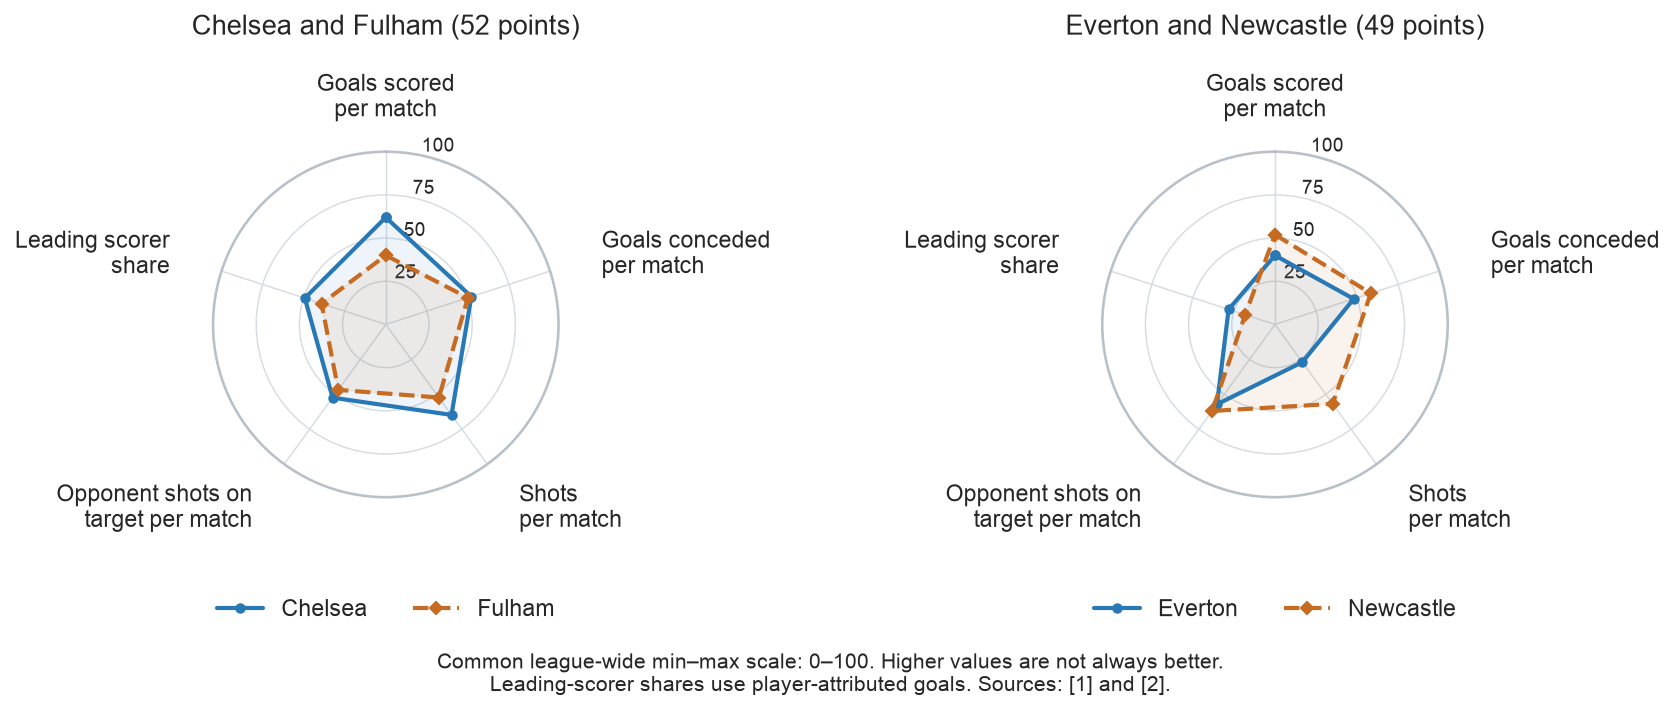

Saved PNG: other_equal_point_radar_profiles.png


In [30]:
fig_other.text(0.5, 0.015,
               'Common league-wide min–max scale: 0–100. Higher values are not always better.\n'
               'Leading-scorer shares use player-attributed goals. Sources: [1] and [2].',
               ha='center', fontsize=10)
other_radar_png_path = data_dir / 'other_equal_point_radar_profiles.png'
fig_other.savefig(other_radar_png_path, dpi=300, bbox_inches='tight', facecolor='white')
display(fig_other)
print('Saved PNG:', other_radar_png_path.name)

### 12.11 Create the grouped bars

Plot goals scored and conceded per match for all six clubs, using the same unit.

In [31]:
positions = np.arange(len(case_profiles))
width = 0.34
club_labels = [f"{row['Team']}\n{row['Points']} pts"
               for row in case_profiles.to_dict('records')]
fig_bar, ax_bar = plt.subplots(figsize=(6.8, 3.25), dpi=150)
plt.close(fig_bar)
scored = ax_bar.bar(positions - width / 2, case_profiles['GoalsPerMatch'],
                    width, label='Goals scored', color='#2878B5')
conceded = ax_bar.bar(positions + width / 2, case_profiles['ConcededPerMatch'],
                      width, label='Goals conceded', color='#C66B21')

### 12.12 Add labels and pair separators

Add values, club names, a legend and separators between the three pairs.

In [32]:
ax_bar.bar_label(scored, fmt='%.2f', padding=3, fontsize=10)
ax_bar.bar_label(conceded, fmt='%.2f', padding=3, fontsize=10)
ax_bar.set_xticks(positions)
ax_bar.set_xticklabels(club_labels, fontsize=10)
ax_bar.set_ylabel('Goals per match', fontsize=11)
ax_bar.set_ylim(0, 1.95)
ax_bar.set_title('Goal rates for all three equal-point pairs', fontsize=13, pad=32)
ax_bar.legend(loc='lower right', bbox_to_anchor=(1, 1.01), ncol=2, frameon=False, fontsize=10)
for boundary in [1.5, 3.5]:
    ax_bar.axvline(boundary, color='#C8D0D7', linestyle=':', linewidth=0.8)
ax_bar.grid(axis='x', visible=False)
sns.despine(ax=ax_bar)

### 12.13 Display and save Figure 3

Save the PNG and display the completed chart.

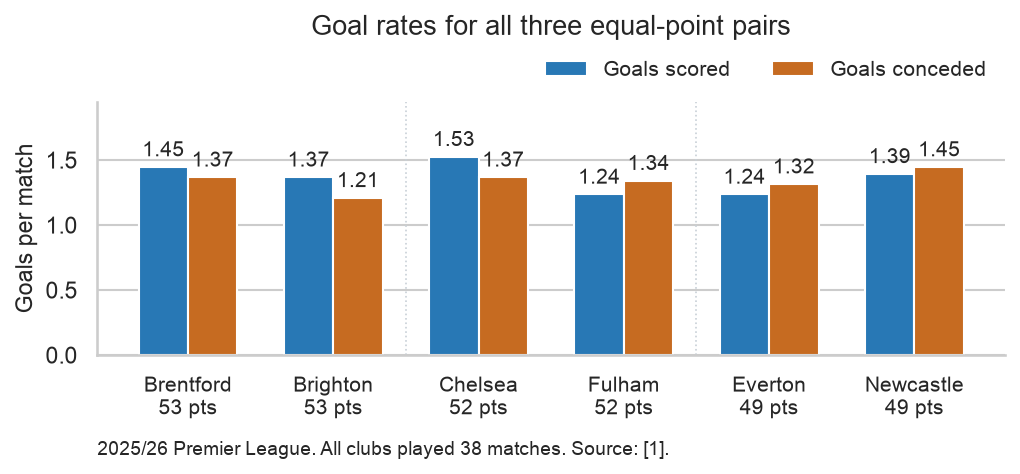

Saved PNG: equal_points_comparison.png


In [33]:
fig_bar.subplots_adjust(left=0.10, right=0.99, bottom=0.24, top=0.76)
fig_bar.text(0.10, 0.035, '2025/26 Premier League. All clubs played 38 matches. Source: [1].', fontsize=9)
bar_png_path = data_dir / 'equal_points_comparison.png'
fig_bar.savefig(bar_png_path, dpi=300, bbox_inches='tight', facecolor='white')
display(fig_bar)
print('Saved PNG:', bar_png_path.name)

## Data sources

1. [DataHub English Premier League football](https://datahub.io/football/english-premier-league).
   Match file: `season-2526.csv`. Original provider: Football Data UK.
2. [Football Players Stats 2025–2026 on Kaggle](https://www.kaggle.com/datasets/hubertsidorowicz/football-players-stats-2025-2026).
   Player file: `players_data-2025_2026.csv`.